# Partie 3 — Modèles autorégressifs de séquences
**Binôme : Amjad AAYD et [information masquée] — [information masquée] — 6 octobre 2026**

Enseignant : [information masquée]. Groupe : à compléter.
Source : Introduction aux modèles génératifs, huit pages, 20 avril 2026. Résultats exécutés, graines fixées.


In [1]:
%matplotlib inline
import sys, json, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import sklearn
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)
torch.set_default_dtype(torch.float64)
torch.set_num_threads(2)
torch.manual_seed(44)
rng = np.random.default_rng(44)
figdir = Path("figures")
figdir.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .2})
def save(fig, name):
    fig.savefig(figdir / (name + ".png"), dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| PyTorch", torch.__version__, "| scikit-learn", sklearn.__version__)
print("Calcul CPU, float64, deux threads ; graine =", 44)


Python 3.12.10 | NumPy 2.3.5 | PyTorch 2.12.0.dev20260408+cu128 | scikit-learn 1.8.0
Calcul CPU, float64, deux threads ; graine = 44


## Factorisation autorégressive
Pour quatre tokens : p(x₁,x₂,x₃,x₄)=p(x₁)p(x₂|x₁)p(x₃|x₁,x₂)p(x₄|x₁,x₂,x₃). La chaîne d'ordre 1 remplace l'historique par le dernier token ; celle d'ordre 2 par les deux derniers. La NLL d'une séquence est −Σ log p(xₜ|contexte). On compte le token de fin et le premier token depuis un état de début ; les unités sont des nats (log naturel).

## 3.1 Texte français : tokenisation et structure creuse
Un corpus pédagogique local est fourni dans corpus_francais.txt. Un tokenizeur simple conserve les mots accentués, les apostrophes internes et les points. La casse est conservée pour commencer par « Une ». Les dictionnaires stockent seulement les transitions observées, au lieu d’une matrice V×V principalement nulle. Ils évitent aussi une dépendance à des ressources nltk externes, autorisée par le sujet.

In [2]:
import re
from collections import Counter,defaultdict
np.random.seed(44)
corpus_francais="""Une image représente un chiffre.
Une image contient des pixels.
Une image moyenne contient des traits superposés.
Une image générée représente une variation autour de la moyenne.
Une variable latente suit une loi gaussienne.
Une loi gaussienne possède une moyenne et une covariance.
Une covariance décrit les variations des pixels.
Une matrice de covariance contient des corrélations.
Une direction principale décrit une variation des pixels.
Une direction latente modifie les traits du chiffre.
Une chaîne de Markov génère une phrase.
Une phrase contient des mots.
Une probabilité de transition dépend du dernier mot.
Une transition observée reçoit une probabilité positive.
Une estimation utilise les données pour apprendre une distribution.
Une distribution apprise permet de générer une image.
Une génération produit de nouvelles observations.
Une séquence possède un début et une fin.
Une fin de phrase correspond à un point.
Une phrase générée peut manquer de cohérence.
"""
Path('corpus_francais.txt').write_text(corpus_francais,encoding='utf-8')
def tokenize(text):return re.findall(r"[A-Za-zÀ-ÖØ-öø-ÿ]+(?:['’][A-Za-zÀ-ÖØ-öø-ÿ]+)*|[.]",text)
corpus=tokenize(corpus_francais)
vocab=sorted(set(corpus));word_to_index={w:i for i,w in enumerate(vocab)}
def make_pairs(corpus):
    yield from zip(corpus,corpus[1:])
def build_transition_matrix(corpus):
    d=defaultdict(Counter)
    for w1,w2 in make_pairs(corpus):d[w1][w2]+=1
    return {w1:dict(row) for w1,row in d.items()}
transition_matrix=build_transition_matrix(corpus)
counts_pairs=Counter(make_pairs(corpus))
assert sum(counts_pairs.values())==len(corpus)-1
assert sum(sum(row.values()) for row in transition_matrix.values())==len(corpus)-1
print('Tokens :',len(corpus),'Vocabulaire unique :',len(vocab),'Transitions observées distinctes :',len(counts_pairs))
print('10 bigrammes les plus fréquents :')
for pair,c in counts_pairs.most_common(10):print(pair,':',c)
print('Matrice dense :',len(vocab)**2,'cases ; dictionnaire :',len(counts_pairs),'transitions stockées.')


Tokens : 166 Vocabulaire unique : 70 Transitions observées distinctes : 131
10 bigrammes les plus fréquents :
('.', 'Une') : 19
('Une', 'image') : 4
('contient', 'des') : 4
('des', 'pixels') : 3
('pixels', '.') : 3
('chiffre', '.') : 2
('une', 'variation') : 2
('loi', 'gaussienne') : 2
('et', 'une') : 2
('Une', 'direction') : 2
Matrice dense : 4900 cases ; dictionnaire : 131 transitions stockées.


Phrase commençant par Une : Une distribution.
Arrêt sur le point : True
Cinq générations supplémentaires :
Une transition dépend du dernier mot. [terminée]
Une chaîne de cohérence. [terminée]
Une direction principale décrit une fin de nouvelles observations. [terminée]
Une image moyenne et une probabilité positive. [terminée]
Une phrase. [terminée]


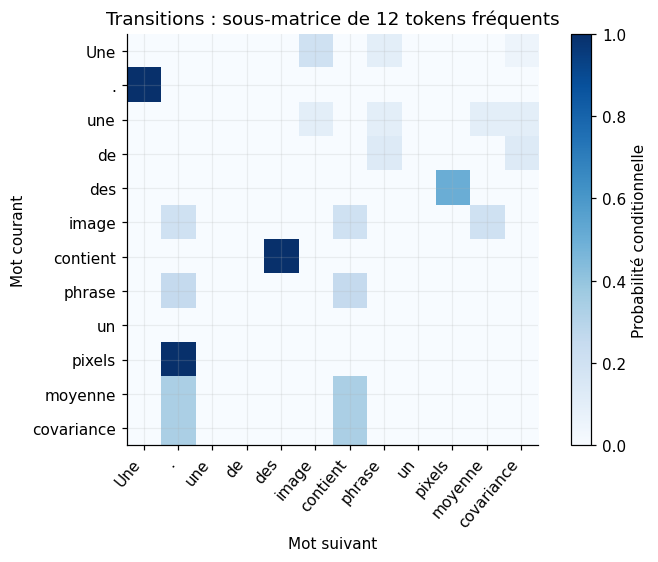

In [3]:
def sample_next_word(word,transition_matrix):
    if word not in transition_matrix:raise KeyError('Aucune transition sortante pour '+word)
    row=transition_matrix[word];words=list(row);counts=np.array([row[w] for w in words],dtype=float)
    probs=counts/counts.sum();assert np.isclose(probs.sum(),1)
    return str(np.random.choice(words,p=probs))
def generate_sentence(start='Une',max_tokens=50):
    words=[start]
    for _ in range(max_tokens-1):
        words.append(sample_next_word(words[-1],transition_matrix))
        if words[-1]=='.':return ' '.join(words).replace(' .','.'),True
    return ' '.join(words),False
phrase,terminee=generate_sentence()
print('Phrase commençant par Une :',phrase)
print('Arrêt sur le point :',terminee)
assert phrase.startswith('Une ') and terminee
print('Cinq générations supplémentaires :')
phrases=[generate_sentence() for _ in range(5)]
for phrase_i,end in phrases:print(phrase_i,'[terminée]' if end else '[limite atteinte]')
# Sous-matrice : les probabilités sont normalisées sur toutes les sorties,
# mais seule une sélection de colonnes est affichée.
topwords=[w for w,_ in Counter(corpus).most_common(12)]
Pview=np.array([[transition_matrix.get(w,{}).get(v,0)/max(1,sum(transition_matrix.get(w,{}).values())) for v in topwords] for w in topwords])
fig,ax=plt.subplots(figsize=(7,5),layout='constrained')
im=ax.imshow(Pview,cmap='Blues',vmin=0,vmax=1);ax.set_xticks(range(12),topwords,rotation=50,ha='right');ax.set_yticks(range(12),topwords)
ax.set(xlabel='Mot suivant',ylabel='Mot courant',title='Transitions : sous-matrice de 12 tokens fréquents')
fig.colorbar(im,ax=ax,label='Probabilité conditionnelle')
save(fig,'13_markov_texte')


### Approfondissement texte : ordre 2
La génération utilise deux mots de contexte, avec un token de début explicite. Les observations sont séparées par phrase pour éviter d’apprendre une transition entre deux phrases. Si un contexte n’est pas observé, le code recule vers les probabilités d’ordre 1 ; cette règle de secours est explicitée, sans prétendre résoudre la cohérence sémantique.

In [4]:
tri_fr=defaultdict(Counter)
for sentence in corpus_francais.strip().splitlines():
    toks=['<bos>']+tokenize(sentence)
    for a,b,c in zip(toks,toks[1:],toks[2:]):tri_fr[(a,b)][c]+=1
def generate_sentence_order2(start='Une',max_tokens=50):
    words=['<bos>',start]
    for _ in range(max_tokens-1):
        row=tri_fr.get(tuple(words[-2:]))
        if row:
            keys=list(row);cnt=np.array(list(row.values()),float);nxt=str(np.random.choice(keys,p=cnt/cnt.sum()))
        else:nxt=sample_next_word(words[-1],transition_matrix)
        words.append(nxt)
        if nxt=='.':return ' '.join(words[1:]).replace(' .','.'),True
    return ' '.join(words[1:]),False
phrases2=[generate_sentence_order2() for _ in range(5)]
print('Texte ordre 2 :')
for phrase_i,end in phrases2:print(phrase_i,'[terminée]' if end else '[limite atteinte]')


Texte ordre 2 :
Une image représente un chiffre. [terminée]
Une fin de phrase correspond à un point. [terminée]
Une transition observée reçoit une probabilité positive. [terminée]
Une direction principale décrit une variation autour de la moyenne. [terminée]
Une covariance décrit les variations des pixels. [terminée]


## 3.2 Séquences symboliques, ordre 1 et lissage
V={A,B,C,D,⟨eos⟩}, corpus exact de quatre séquences. On ajoute ⟨bos⟩ uniquement comme contexte de départ. Pour l'ordre 1 : p(x₁,…,x₄)=p(x₁|bos)×p(x₂|x₁)×p(x₃|x₂)×p(x₄|x₃). Le lissage Laplace α=1 donne (compte(c,w)+α)/(total(c)+α|V|). Les transitions du token eos ne sont pas nécessaires, car la génération s'arrête sur eos. On n'utilise pas les échantillons générés comme corpus d'entraînement.

In [5]:
V=['A','B','C','D','<eos>'];BOS='<bos>'
sequences=[['A','B','C','<eos>'],['A','B','D','<eos>'],['A','C','D','<eos>'],['B','C','D','<eos>']]
index={w:i for i,w in enumerate(V)}
def fit_counts(seqs,order):
    counts=defaultdict(Counter)
    for seq in seqs:
        padded=[BOS]*order+seq
        for t in range(order,len(padded)):counts[tuple(padded[t-order:t])][padded[t]]+=1
    return dict(counts)
def conditional_probs(context,counts,alpha):
    row=counts.get(tuple(context),{})
    c=np.array([row.get(w,0) for w in V],dtype=float)
    denom=c.sum()+alpha*len(V)
    if denom==0:raise ValueError('Contexte non observé sans lissage : '+str(context))
    probs=(c+alpha)/denom
    assert np.all(probs>=0) and np.isclose(probs.sum(),1)
    return probs
def sequence_nll(seq,counts,order,alpha):
    padded=[BOS]*order+seq;loss=0.
    for t in range(order,len(padded)):
        p=conditional_probs(padded[t-order:t],counts,alpha)[index[padded[t]]]
        if p==0:return float('inf')
        loss-=math.log(p)
    return loss
def generate_symbolic(counts,order,alpha,n=20,max_tokens=15):
    samples=[]
    for _ in range(n):
        history=[BOS]*order;tokens=[];ended=False
        for _ in range(max_tokens):
            probs=conditional_probs(history[-order:],counts,alpha)
            word=str(rng.choice(V,p=probs));tokens.append(word);history.append(word)
            if word=='<eos>':ended=True;break
        samples.append({'tokens':tokens,'terminee':ended})
    return samples
counts1=fit_counts(sequences,1)
for context,row in sorted(counts1.items()):
    print(context,'comptes :',dict(row),'probas MLE :',np.round(conditional_probs(context,counts1,0),4),'Laplace :',np.round(conditional_probs(context,counts1,1),4))
nll={};generated={}
for alpha in [0,1]:
    losses=[sequence_nll(seq,counts1,1,alpha) for seq in sequences]
    nll[(1,alpha)]={'par_sequence':float(np.mean(losses)),'par_token':float(sum(losses)/sum(map(len,sequences)))}
    generated[(1,alpha)]=generate_symbolic(counts1,1,alpha)
    print('Ordre 1, alpha =',alpha,'NLL :',nll[(1,alpha)])
    print('20 séquences générées :')
    for j,item in enumerate(generated[(1,alpha)],1):print(j,' '.join(item['tokens']),'[limite atteinte]' if not item['terminee'] else '')
assert np.all(np.array([sequence_nll(seq,counts1,1,0) for seq in sequences])<np.inf)
assert nll[(1,1)]['par_sequence']>=nll[(1,0)]['par_sequence']-1e-12
# Toute sortie a une probabilité strictement positive avec Laplace.
assert all(np.all(conditional_probs(c,counts1,1)>0) for c in counts1)


('<bos>',) comptes : {'A': 3, 'B': 1} probas MLE : [0.75 0.25 0.   0.   0.  ] Laplace : [0.4444 0.2222 0.1111 0.1111 0.1111]
('A',) comptes : {'B': 2, 'C': 1} probas MLE : [0.     0.6667 0.3333 0.     0.    ] Laplace : [0.125 0.375 0.25  0.125 0.125]
('B',) comptes : {'C': 2, 'D': 1} probas MLE : [0.     0.     0.6667 0.3333 0.    ] Laplace : [0.125 0.125 0.375 0.25  0.125]
('C',) comptes : {'<eos>': 1, 'D': 2} probas MLE : [0.     0.     0.     0.6667 0.3333] Laplace : [0.125 0.125 0.125 0.375 0.25 ]
('D',) comptes : {'<eos>': 3} probas MLE : [0. 0. 0. 0. 1.] Laplace : [0.125 0.125 0.125 0.125 0.5  ]
Ordre 1, alpha = 0 NLL : {'par_sequence': 1.9944920232821373, 'par_token': 0.4986230058205343}
20 séquences générées :
1 A B C <eos> 
2 A C D <eos> 
3 A B D <eos> 
4 B D <eos> 
5 A C <eos> 
6 A B C <eos> 
7 A B C D <eos> 
8 A C <eos> 
9 A B D <eos> 
10 A B D <eos> 
11 A B D <eos> 
12 B D <eos> 
13 B D <eos> 
14 A B D <eos> 
15 A C D <eos> 
16 B C D <eos> 
17 A C D <eos> 
18 B C <eos> 
19 

## 3.3 Modèle d'ordre 2 : paramètres, sparsité et qualité
p(xₜ|xₜ₋₁,xₜ₋₂) utilise deux tokens de contexte. Pour un vocabulaire de taille V, un tableau complet possède V²(V−1) paramètres libres contre V(V−1) à l'ordre 1, hors convention spéciale de début/fin. Dans notre implémentation, eos n'est jamais un contexte actif. Les contextes valides de début et les contextes internes sont dénombrés explicitement ci-dessous.

La NLL d'entraînement peut diminuer avec l'ordre 2, mais cela ne prouve pas une meilleure généralisation. Le petit corpus laisse de nombreuses paires de contexte non observées ; le lissage leur donne une distribution uniforme. On mesure la diversité, l'arrêt sur eos et l'appartenance exacte au corpus, indicateurs descriptifs de cet exercice jouet, pas scores de cohérence du français.

Ordre 2, alpha = 0 NLL : {'par_sequence': 1.7328679513998635, 'par_token': 0.4332169878499659}
1 A C D <eos> 
2 A C D <eos> 
3 B C <eos> 
4 A C D <eos> 
5 A B D <eos> 
6 A B D <eos> 
7 B C D <eos> 
8 A B C <eos> 
9 A C D <eos> 
10 A B D <eos> 
11 A B C D <eos> 
12 A B D <eos> 
13 A B C <eos> 
14 A B C D <eos> 
15 A C D <eos> 
16 A B D <eos> 
17 A C D <eos> 
18 A B C D <eos> 
19 B C D <eos> 
20 B C D <eos> 
Ordre 2, alpha = 1 NLL : {'par_sequence': 4.321576343332203, 'par_token': 1.0803940858330507}
1 C C C A A B A A D A D B C <eos> 
2 B C B A D <eos> 
3 A B D A A <eos> 
4 A B C B D A <eos> 
5 <eos> 
6 D B D <eos> 
7 A C A D A A B C D D <eos> 
8 A A D B C A A C <eos> 
9 A B A B D <eos> 
10 A <eos> 
11 B C <eos> 
12 B C D <eos> 
13 B B C B C <eos> 
14 A B D B B C D A A D C B B D <eos> 
15 C D D C B B <eos> 
16 A C B C <eos> 
17 <eos> 
18 A A <eos> 
19 C <eos> 
20 D C D B B C <eos> 
Structures : {'ordre1': {'contextes_possibles': 5, 'contextes_observes': 5, 'parametres_libres_table_comple

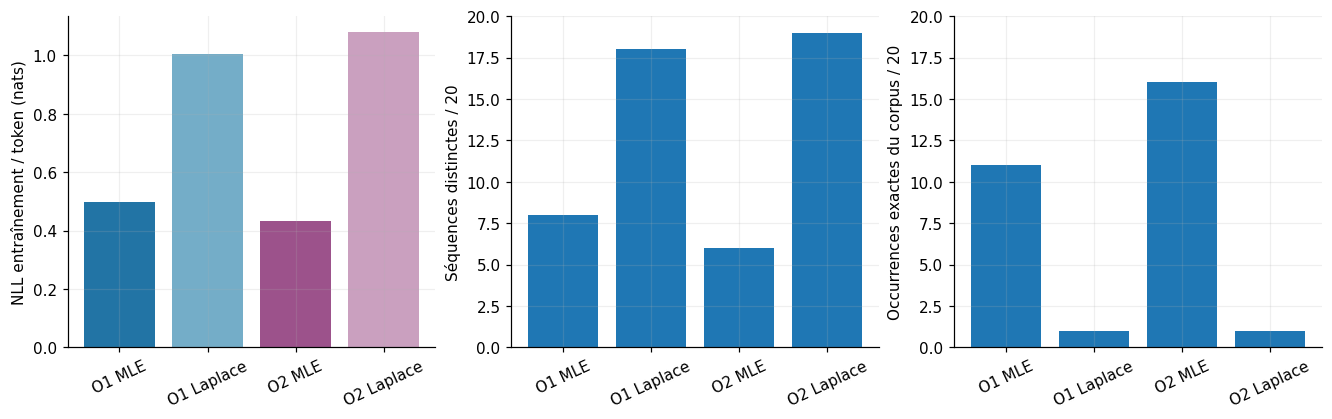

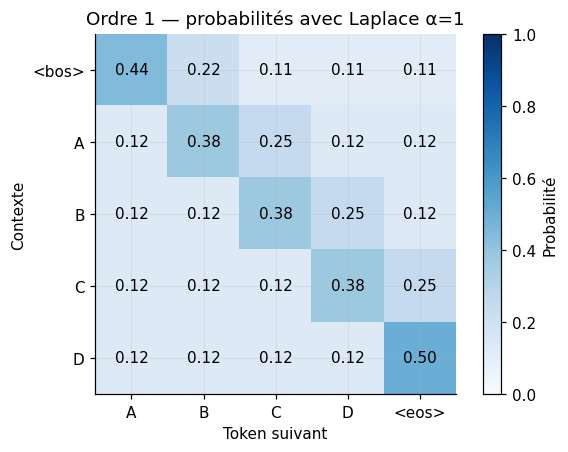

Partie 3 : tous les contrôles ont réussi.


In [6]:
counts2=fit_counts(sequences,2)
for alpha in [0,1]:
    losses=[sequence_nll(seq,counts2,2,alpha) for seq in sequences]
    nll[(2,alpha)]={'par_sequence':float(np.mean(losses)),'par_token':float(sum(losses)/sum(map(len,sequences)))}
    generated[(2,alpha)]=generate_symbolic(counts2,2,alpha)
    print('Ordre 2, alpha =',alpha,'NLL :',nll[(2,alpha)])
    for j,item in enumerate(generated[(2,alpha)],1):print(j,' '.join(item['tokens']),'[limite atteinte]' if not item['terminee'] else '')
assert nll[(2,0)]['par_sequence']<=nll[(1,0)]['par_sequence']+1e-10
# 4 tokens non terminaux ; V=5 sorties possibles ; BOS géré à part.
possible_contexts1=1+4 # BOS et chacun des quatre symboles non terminaux
possible_contexts2=1+4+4**2 # (BOS,BOS), (BOS,symbole), paires internes
structural={
    'ordre1':{'contextes_possibles':possible_contexts1,'contextes_observes':len(counts1),'parametres_libres_table_complete':possible_contexts1*(len(V)-1),'transitions_observees':sum(len(row) for row in counts1.values())},
    'ordre2':{'contextes_possibles':possible_contexts2,'contextes_observes':len(counts2),'parametres_libres_table_complete':possible_contexts2*(len(V)-1),'transitions_observees':sum(len(row) for row in counts2.values())}}
trainset={tuple(seq) for seq in sequences};quality={}
for key,samples in generated.items():
    quality[key]={'uniques':len({tuple(s['tokens']) for s in samples}),
                  'terminees':sum(s['terminee'] for s in samples),
                  'presentes_dans_corpus':sum(tuple(s['tokens']) in trainset for s in samples),
                  'longueur_moyenne':float(np.mean([len(s['tokens']) for s in samples]))}
print('Structures :',structural)
print('Qualité descriptive des lots de 20 :',quality)
fig,ax=plt.subplots(1,3,figsize=(12,3.7),layout='constrained')
keys=[(1,0),(1,1),(2,0),(2,1)];names=['O1 MLE','O1 Laplace','O2 MLE','O2 Laplace']
ax[0].bar(names,[nll[k]['par_token'] for k in keys],color=['#2274A5','#74ADC8','#9C528B','#CAA0BF']);ax[0].set_ylabel('NLL entraînement / token (nats)')
ax[1].bar(names,[quality[k]['uniques'] for k in keys]);ax[1].set(ylabel='Séquences distinctes / 20',ylim=(0,20))
ax[2].bar(names,[quality[k]['presentes_dans_corpus'] for k in keys]);ax[2].set(ylabel='Occurrences exactes du corpus / 20',ylim=(0,20))
for a in ax:a.tick_params(axis='x',rotation=25)
save(fig,'14_sequences_comparaison')
P1=np.array([conditional_probs((w,),counts1,1) for w in [BOS,'A','B','C','D']])
fig,ax=plt.subplots(figsize=(6,4),layout='constrained')
im=ax.imshow(P1,cmap='Blues',vmin=0,vmax=1);ax.set_xticks(range(5),V);ax.set_yticks(range(5),[BOS,'A','B','C','D']);ax.set(xlabel='Token suivant',ylabel='Contexte',title='Ordre 1 — probabilités avec Laplace α=1')
for i in range(5):
    for j in range(5):ax.text(j,i,f'{P1[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im,ax=ax,label='Probabilité')
save(fig,'15_laplace_transitions')
metrics={'texte':{'tokens':len(corpus),'vocabulaire':len(vocab),'bigrammes_distincts':len(counts_pairs),'top10':[[list(pair),cnt] for pair,cnt in counts_pairs.most_common(10)],'phrase':phrase,'terminee':bool(terminee),'autres_phrases':phrases,'phrases_ordre2':phrases2},
         'nll':{f'ordre{o}_alpha{a}':v for (o,a),v in nll.items()},'structures':structural,
         'qualite_lots20':{f'ordre{o}_alpha{a}':v for (o,a),v in quality.items()}}
Path('metriques_partie3.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')
Path('sequences_generees.json').write_text(json.dumps({f'ordre{o}_alpha{a}':v for (o,a),v in generated.items()},ensure_ascii=False,indent=2),encoding='utf-8')
print('Partie 3 : tous les contrôles ont réussi.')


## Discussion
Sans lissage, les transitions non vues sont impossibles ; avec Laplace, elles deviennent possibles au prix d’une NLL d’entraînement plus élevée et de séquences parfois atypiques. La génération est arrêtée sur eos ou sur une limite de 15 tokens ; les séquences tronquées sont explicitement signalées, sans ajouter artificiellement eos. L’ordre 2 décrit plus précisément les contextes, mais demande plus de paramètres et davantage de données. Une meilleure NLL sur ces quatre exemples ne constitue pas une preuve de généralisation ; une étude séparée avec corpus de validation serait nécessaire.